# Airline Passenger Satisfaction Prediction - ANN

- **Data Cleaning**: Handled missing value imputation for arrival delays and renamed features for consistency.
- **Feature Selection**: Conducted Chi-Square and ANOVA statistical tests to filter out non-significant features (dropping `'Gate_location'`).
- **Pre-processing**: Encoded categorical fields and applied random under-sampling to balance the satisfaction classes evenly.
- **Modeling**: Implemented a Deep Artificial Neural Network (ANN) classifier using TensorFlow, optimized with Binary Crossentropy and evaluated on accuracy.

In [67]:
import pandas as pd
import numpy as np
import matplotlib as plt
import seaborn as sns

In [68]:
df = pd.read_csv('/Users/sudharsank/AIML/datasets/Airline-Satisfaction-Data.csv')

In [69]:
df.head()

,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Seat comfort,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,5,3,3,4,4,3,3,0,0.0,True


In [70]:
df['satisfaction'].unique()

array([False,  True])

In [71]:
df.shape

(129880, 22)

In [72]:
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight Distance', 'Inflight wifi service',
       'Departure/Arrival time convenient', 'Ease of Online booking',
       'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort',
       'Inflight entertainment', 'On-board service', 'Leg room service',
       'Baggage handling', 'Checkin service', 'Cleanliness',
       'Departure Delay in Minutes', 'Arrival Delay in Minutes',
       'satisfaction'],
      dtype='str')

In [73]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  str    
 1   Customer Type                      129880 non-null  str    
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  str    
 4   Class                              129880 non-null  str    
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding                    129880 non-null

In [74]:
df.isnull().sum()

Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64

In [75]:
df['Arrival Delay in Minutes'].unique()

array([1.800e+01, 6.000e+00, 0.000e+00, 9.000e+00, 2.300e+01, 8.000e+00,
       3.500e+01, 5.100e+01, 1.000e+01, 5.000e+00, 4.000e+00, 2.900e+01,
       4.400e+01, 2.800e+01, 1.200e+01, 1.200e+02, 2.400e+01, 1.000e+00,
       2.000e+01, 3.100e+01, 1.500e+01, 4.800e+01, 2.600e+01, 4.900e+01,
       2.000e+00, 3.700e+01, 5.000e+01, 3.000e+00, 1.900e+01, 7.200e+01,
       1.100e+01, 3.400e+01, 6.200e+01, 2.700e+01, 5.200e+01, 1.300e+01,
       8.200e+01, 3.000e+01, 1.600e+01, 7.000e+00, 1.220e+02, 1.790e+02,
       1.250e+02, 1.700e+01,       nan, 8.900e+01, 1.010e+02, 1.400e+01,
       6.100e+01, 3.200e+01, 3.300e+01, 4.100e+01, 1.910e+02, 1.380e+02,
       5.300e+01, 2.200e+01, 5.700e+01, 6.500e+01, 7.600e+01, 1.070e+02,
       9.200e+01, 1.640e+02, 2.100e+01, 4.000e+01, 5.500e+01, 1.850e+02,
       6.300e+01, 7.700e+01, 8.600e+01, 9.100e+01, 1.000e+02, 5.400e+01,
       3.600e+01, 7.000e+01, 1.390e+02, 6.700e+01, 1.630e+02, 1.280e+02,
       1.800e+02, 9.300e+01, 1.210e+02, 4.500e+01, 

In [76]:
df['Arrival Delay in Minutes'] = df['Arrival Delay in Minutes'].fillna(df['Arrival Delay in Minutes'].mean())

In [77]:
df.isnull().sum()

Gender                               0
Customer Type                        0
Age                                  0
Type of Travel                       0
Class                                0
Flight Distance                      0
Inflight wifi service                0
Departure/Arrival time convenient    0
Ease of Online booking               0
Gate location                        0
Food and drink                       0
Online boarding                      0
Seat comfort                         0
Inflight entertainment               0
On-board service                     0
Leg room service                     0
Baggage handling                     0
Checkin service                      0
Cleanliness                          0
Departure Delay in Minutes           0
Arrival Delay in Minutes             0
satisfaction                         0
dtype: int64

In [78]:
df.duplicated().sum()

np.int64(0)

In [79]:
df = df.rename(columns={
    'Flight Distance': 'Flight_Distance',
    'Inflight wifi service': 'Inflight_wifi_service',
    'Departure/Arrival time convenient': 'Departure_Arrival_time_convenient',
    'Ease of Online booking': 'Ease_of_Online_booking',
    'Gate location': 'Gate_location',
    'Food and drink': 'Food_and_drink',
    'Online boarding': 'Online_boarding',
    'Seat comfort': 'Seat_comfort',
    'Inflight entertainment': 'Inflight_entertainment',
    'On-board service': 'On_board_service',
    'Leg room service': 'Leg_room_service',
    'Baggage handling': 'Baggage_handling',
    'Departure Delay in Minutes': 'Departure_Delay_in_Minutes',
    'Arrival Delay in Minutes': 'Arrival_Delay_in_Minutes',
    'Checkin service': 'Checkin_service',
})

In [80]:
cat_cols = df.select_dtypes(include=object).columns.tolist()
cat_cols


/var/folders/7b/5_gy8f1j7171y56xbfvy4r7h0000gn/T/ipykernel_43393/4045066859.py:1: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/dev/user_guide/migration.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  cat_cols = df.select_dtypes(include=object).columns.tolist()


['Gender', 'Customer Type', 'Type of Travel', 'Class']

In [81]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Gender'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')


satisfaction  False  True 
Gender                    
Female        37630  28269
Male          35822  28159
chi2: 16.35, p-value: 0.0001, alpha: 0.05, significant: True, DOF: 1


In [82]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Customer Type'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')


satisfaction       False  True 
Customer Type                  
Loyal Customer     55372  50728
disloyal Customer  18080   5700
chi2: 4493.19, p-value: 0.0000, alpha: 0.05, significant: True, DOF: 1


In [83]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Type of Travel'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, significant: {p < alpha}, DOF: {dof}')


satisfaction     False  True 
Type of Travel               
Business travel  37337  52356
Personal Travel  36115   4072
chi2: 26282.52, p-value: 0.0000, alpha: 0.05, significant: True, DOF: 1


In [84]:
# chi-square
from scipy.stats import chi2_contingency

table = pd.crosstab(df['Class'], df['satisfaction'])
print(table)

chi2, p, dof, expected = chi2_contingency(table)
alpha = 0.05
print(f'chi2: {chi2:.2f}, p-value: {p:.4f}, alpha: {alpha}, \nsignificant: {p < alpha}, DOF: {dof}')


satisfaction  False  True 
Class                     
Business      18994  43166
Eco           47366  10943
Eco Plus       7092   2319
chi2: 32906.17, p-value: 0.0000, alpha: 0.05, 
significant: True, DOF: 2


In [85]:
num_cols = df.select_dtypes(include=np.number).columns.tolist()
num_cols


['Age',
 'Flight_Distance',
 'Inflight_wifi_service',
 'Departure_Arrival_time_convenient',
 'Ease_of_Online_booking',
 'Gate_location',
 'Food_and_drink',
 'Online_boarding',
 'Seat_comfort',
 'Inflight_entertainment',
 'On_board_service',
 'Leg_room_service',
 'Baggage_handling',
 'Checkin_service',
 'Cleanliness',
 'Departure_Delay_in_Minutes',
 'Arrival_Delay_in_Minutes']

In [86]:
df['Gate_location'].unique()

array([1, 3, 2, 5, 4, 0])

In [87]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Age ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq        mean_sq            F  PR(>F)
C(satisfaction)       1.0  5.338344e+05  533834.397969  2378.024191     0.0
Residual         129878.0  2.915586e+07     224.486530          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [88]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Flight_Distance ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0  1.148162e+10  1.148162e+10  12665.660936     0.0
Residual         129878.0  1.177365e+11  9.065160e+05           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [89]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Inflight_wifi_service ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   18441.465968  18441.465968  11347.420455     0.0
Residual         129878.0  211073.585087      1.625168           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [90]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Departure_Arrival_time_convenient ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq     mean_sq           F        PR(>F)
C(satisfaction)       1.0     891.630588  891.630588  383.646795  2.657334e-85
Residual         129878.0  301848.468881    2.324092         NaN           NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [91]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Ease_of_Online_booking ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq      mean_sq            F  PR(>F)
C(satisfaction)       1.0    7278.055294  7278.055294  3812.792979     0.0
Residual         129878.0  247917.804815     1.908851          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [92]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Gate_location ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq   mean_sq         F  PR(>F)
C(satisfaction)       1.0       1.656460  1.656460  1.013366  0.3141
Residual         129878.0  212300.187326  1.634612       NaN     NaN
C(satisfaction)    False
Residual           False
Name: PR(>F), dtype: bool


In [93]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Food_and_drink ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq            F  PR(>F)
C(satisfaction)       1.0   10260.363930  10260.363930  6072.171356     0.0
Residual         129878.0  219459.476415      1.689736          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [94]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Online_boarding ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   59654.411850  59654.411850  43698.252161     0.0
Residual         129878.0  177302.187596      1.365144           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [95]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Seat_comfort ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   27507.097704  27507.097704  17993.257439     0.0
Residual         129878.0  198550.309625      1.528745           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [96]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Inflight_entertainment ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   36657.124828  36657.124828  24479.573892     0.0
Residual         129878.0  194486.802728      1.497458           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [97]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'On_board_service ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   22337.118864  22337.118864  15045.355578     0.0
Residual         129878.0  192823.646389      1.484652           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [98]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Leg_room_service ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   21963.682100  21963.682100  14048.467148     0.0
Residual         129878.0  203054.117838      1.563422           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [99]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Baggage_handling ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq            F  PR(>F)
C(satisfaction)       1.0   11184.136829  11184.136829  8561.323382     0.0
Residual         129878.0  169666.914595      1.306356          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [100]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Checkin_service  ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq            F  PR(>F)
C(satisfaction)       1.0   11720.727704  11720.727704  7746.713816     0.0
Residual         129878.0  196504.570694      1.512994          NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [101]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Cleanliness ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df         sum_sq       mean_sq             F  PR(>F)
C(satisfaction)       1.0   21129.753372  21129.753372  13517.980514     0.0
Residual         129878.0  203010.361318      1.563085           NaN     NaN
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [102]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Departure_Delay_in_Minutes ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq        mean_sq           F  \
C(satisfaction)       1.0  4.846509e+05  484650.891230  335.238409   
Residual         129878.0  1.877634e+08    1445.690225         NaN   

                       PR(>F)  
C(satisfaction)  8.634339e-75  
Residual                  NaN  
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [103]:
# anova
from statsmodels.stats.anova import _get_covariance, anova_lm
from statsmodels.formula.api import ols
formula = 'Arrival_Delay_in_Minutes ~ C(satisfaction)'
model = ols(formula, df).fit()
aov_table = anova_lm(model)
print(aov_table)
p_value = aov_table['PR(>F)']
print(p_value < alpha)

                       df        sum_sq        mean_sq           F  \
C(satisfaction)       1.0  6.486752e+05  648675.196423  441.231827   
Residual         129878.0  1.909396e+08    1470.145979         NaN   

                       PR(>F)  
C(satisfaction)  8.501049e-98  
Residual                  NaN  
C(satisfaction)     True
Residual           False
Name: PR(>F), dtype: bool


In [104]:
df.shape

(129880, 22)

In [105]:
df = df.drop('Gate_location', axis=1)

In [106]:
df.shape

(129880, 21)

In [107]:
df

,Gender,Customer Type,Age,Type of Travel,Class,Flight_Distance,Inflight_wifi_service,Departure_Arrival_time_convenient,Ease_of_Online_booking,Food_and_drink,...,Seat_comfort,Inflight_entertainment,On_board_service,Leg_room_service,Baggage_handling,Checkin_service,Cleanliness,Departure_Delay_in_Minutes,Arrival_Delay_in_Minutes,satisfaction
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,5,...,5,5,4,3,4,4,5,25,18.0,False
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,1,...,1,1,1,5,3,1,1,1,6.0,False
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,5,...,5,5,4,3,4,4,5,0,0.0,True
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,2,...,2,2,2,5,3,1,2,11,9.0,False
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,4,...,5,3,3,4,4,3,3,0,0.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
129875,Male,disloyal Customer,34,Business travel,Business,526,3,3,3,4,...,4,4,3,2,4,4,4,0,0.0,False
129876,Male,Loyal Customer,23,Business travel,Business,646,4,4,4,4,...,4,4,4,5,5,5,4,0,0.0,True
129877,Female,Loyal Customer,17,Personal Travel,Eco,828,2,5,1,2,...,2,2,4,3,4,5,2,0,0.0,False
129878,Male,Loyal Customer,14,Business travel,Business,1127,3,3,3,4,...,4,4,3,2,5,4,4,0,0.0,True


In [108]:
# df['satisfaction'].value_counts()

In [109]:
# import matplotlib.pyplot as plt
# import seaborn as sns

# sns.countplot(x='satisfaction', data=df)

In [110]:
# from imblearn.under_sampling import RandomUnderSampler

# x = df.drop('satisfaction', axis=1)
# y = df['satisfaction']
# underSamp = RandomUnderSampler()
# x_samp, y_samp = underSamp.fit_resample(x, y)

# y_samp.value_counts()

In [111]:
df.columns

Index(['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class',
       'Flight_Distance', 'Inflight_wifi_service',
       'Departure_Arrival_time_convenient', 'Ease_of_Online_booking',
       'Food_and_drink', 'Online_boarding', 'Seat_comfort',
       'Inflight_entertainment', 'On_board_service', 'Leg_room_service',
       'Baggage_handling', 'Checkin_service', 'Cleanliness',
       'Departure_Delay_in_Minutes', 'Arrival_Delay_in_Minutes',
       'satisfaction'],
      dtype='str')

In [112]:
df.shape

(129880, 21)

In [113]:
from sklearn.preprocessing import OrdinalEncoder
o = OrdinalEncoder()
df[['Gender']] = o.fit_transform(df[['Gender']])
df[['Customer Type']] = o.fit_transform(df[['Customer Type']])
df[['Type of Travel']] = o.fit_transform(df[['Type of Travel']])
df[['Age']] = o.fit_transform(df[['Age']])
df[['Class']] = o.fit_transform(df[['Class']])
df[['Flight_Distance']] = o.fit_transform(df[['Flight_Distance']])
df[['Inflight_wifi_service']] = o.fit_transform(df[['Inflight_wifi_service']])
df[['Departure_Arrival_time_convenient']] = o.fit_transform(df[['Departure_Arrival_time_convenient']])
df[['Ease_of_Online_booking']] = o.fit_transform(df[['Ease_of_Online_booking']])
df[['Food_and_drink']] = o.fit_transform(df[['Food_and_drink']])
df[['Online_boarding']] = o.fit_transform(df[['Online_boarding']])
df[['Seat_comfort']] = o.fit_transform(df[['Seat_comfort']])
df[['Inflight_entertainment']] = o.fit_transform(df[['Inflight_entertainment']])
df[['On_board_service']] = o.fit_transform(df[['On_board_service']])
df[['Leg_room_service']] = o.fit_transform(df[['Leg_room_service']])
df[['Baggage_handling']] = o.fit_transform(df[['Baggage_handling']])
df[['Checkin_service']] = o.fit_transform(df[['Checkin_service']])
df[['Cleanliness']] = o.fit_transform(df[['Cleanliness']])
df[['Departure_Delay_in_Minutes']] = o.fit_transform(df[['Departure_Delay_in_Minutes']])
df[['Arrival_Delay_in_Minutes']] = o.fit_transform(df[['Arrival_Delay_in_Minutes']])

In [114]:
from sklearn.preprocessing import LabelEncoder
o = LabelEncoder()
df['satisfaction'] = o.fit_transform(df['satisfaction'])

In [115]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 21 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  float64
 1   Customer Type                      129880 non-null  float64
 2   Age                                129880 non-null  float64
 3   Type of Travel                     129880 non-null  float64
 4   Class                              129880 non-null  float64
 5   Flight_Distance                    129880 non-null  float64
 6   Inflight_wifi_service              129880 non-null  float64
 7   Departure_Arrival_time_convenient  129880 non-null  float64
 8   Ease_of_Online_booking             129880 non-null  float64
 9   Food_and_drink                     129880 non-null  float64
 10  Online_boarding                    129880 non-null  float64
 11  Seat_comfort                       129880 non-null

In [116]:
df['satisfaction'].value_counts()

satisfaction
0    73452
1    56428
Name: count, dtype: int64

<Axes: xlabel='satisfaction', ylabel='count'>

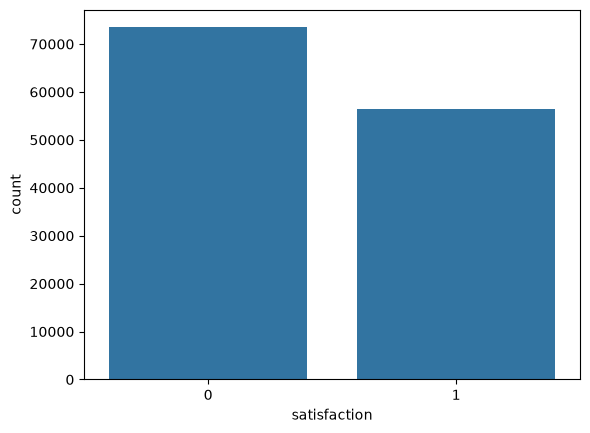

In [117]:
sns.countplot(x='satisfaction', data=df)

In [118]:
x = df.drop('satisfaction', axis=1)
y = df['satisfaction']

In [119]:
from imblearn.under_sampling import RandomUnderSampler

underSamp = RandomUnderSampler()
x_samp, y_samp = underSamp.fit_resample(x, y)

print(y_samp.value_counts())

satisfaction
0    56428
1    56428
Name: count, dtype: int64


In [120]:
from sklearn.model_selection import train_test_split
x_samp_train, x_samp_test, y_samp_train, y_samp_test = train_test_split(x_samp,y_samp, test_size=0.20,random_state=42)
print(x_samp_train.shape)
print(x_samp_test.shape)
print(y_samp_train.shape)
print(y_samp_test.shape)

(90284, 20)
(22572, 20)
(90284,)
(22572,)


In [121]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

x_train_scaled = scaler.fit_transform(x_samp_train)
x_test_scaled = scaler.transform(x_samp_test)

print("Scaling Done!")
print("x_train_scaled shape:", x_train_scaled.shape)

Scaling Done!
x_train_scaled shape: (90284, 20)


In [122]:
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense
import matplotlib.pyplot as plt

# Build and compile the ANN model for binary classification
model = Sequential([
    Dense(500, activation='sigmoid', input_shape=(x_train_scaled.shape[1],)),
    Dense(300, activation='sigmoid'),
    Dense(150, activation='sigmoid'),
    Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])

# Train the model
history = model.fit(
    x_train_scaled,
    y_samp_train,
    epochs=10,
    validation_data=(x_test_scaled, y_samp_test)
)

/Users/sudharsank/AIML/.venv/lib/python3.13/site-packages/keras/src/layers/core/dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Epoch 1/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 6s 2ms/step - accuracy: 0.8894 - loss: 0.2603 - val_accuracy: 0.9112 - val_loss: 0.1958
Epoch 2/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9284 - loss: 0.1644 - val_accuracy: 0.9353 - val_loss: 0.1543
Epoch 3/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9345 - loss: 0.1515 - val_accuracy: 0.9397 - val_loss: 0.1458
Epoch 4/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9382 - loss: 0.1435 - val_accuracy: 0.9427 - val_loss: 0.1358
Epoch 5/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9419 - loss: 0.1374 - val_accuracy: 0.9437 - val_loss: 0.1335
Epoch 6/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9428 - loss: 0.1317 - val_accuracy: 0.9446 - val_loss: 0.1287
Epoch 7/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9453 - loss: 0.1264 - val_accuracy: 0.9437 - val_loss: 0.1273
Epoch 8/10
2822/2822 ━━━━━━━━━━━━━━━━━━━━ 4s 1ms/step - accuracy: 0.9470 - loss: 0.1220 - 

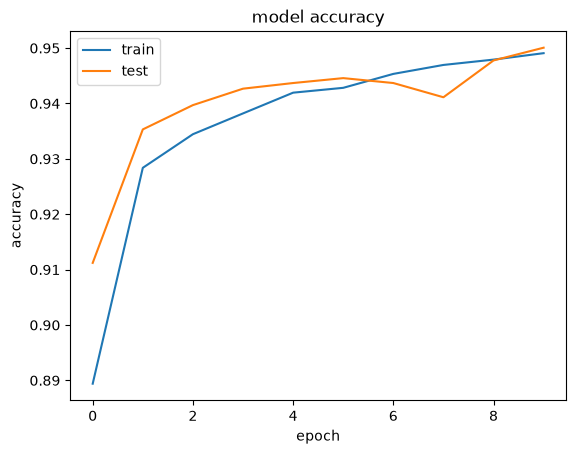

In [123]:
# Plot Model Accuracy
plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()

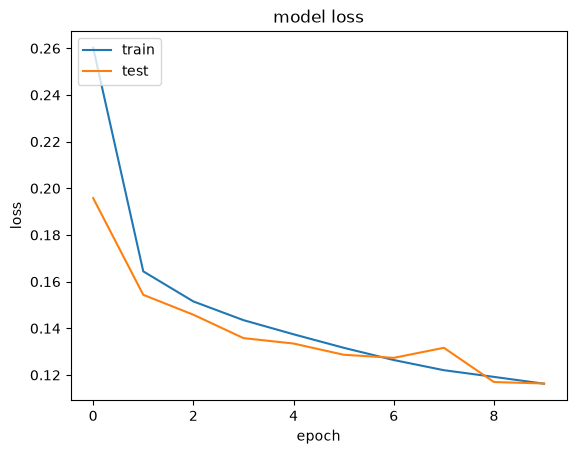

In [124]:
# Plot Model Loss
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'test'], loc='upper left')
plt.show()